# 02 — Baseline Zero-Shot : Depth Anything V2 Small sur Endoscopie

Ce notebook (Étape D.1–D.2) est prêt pour **« Tout exécuter »** sur Google Colab (GPU T4) :
1. Monte Google Drive et localise le dépôt `endo-depth`.
2. Charge le dataset (`c3vd` ou `simcol3d` depuis `MyDrive/endo-depth/data/`). *(Mode démo automatique si le dossier est encore vide.)*
3. Évalue `depth-anything/Depth-Anything-V2-Small-hf` **en zero-shot** (sans réentraînement) avec les 7 métriques standard (`AbsRel`, `SqRel`, `RMSE`, `RMSE log`, `delta < 1.25 / 1.25² / 1.25³`) et alignement d'échelle (`median` et `scale_shift`).
4. Sauvegarde les résultats JSON et les configurations sur Google Drive dans `results/`.

In [1]:
import importlib.util
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# === PARAMÈTRES UTILISATEUR ===
REPO_URL = "https://github.com/hanmaZi/endo-depth.git"
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/endo-depth")
DATASET_NAME = "c3vd"   # "c3vd" ou "simcol3d"
EXPECTED_SEQUENCES = [
    "cecum_t1_a",
    "cecum_t2_a",
    "desc_t4_a",
    "sigmoid_t2_a",
    "sigmoid_t3_a",
    "trans_t1_a",
    "trans_t2_a",
    "trans_t3_a",
    "trans_t3_b",
]
SELECTED_SEQUENCES = list(EXPECTED_SEQUENCES)
CV_FOLD = "sigmoid"  # Pli test par modèle de côlon ("sigmoid", "trans", ou "cecum")
EVAL_SPLIT = "test"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    if Path("/content/endo-depth/.git").is_dir():
        PROJECT_ROOT = Path("/content/endo-depth")
        !git -C {PROJECT_ROOT} pull --ff-only || true
    elif REPO_URL:
        !git clone {REPO_URL} /content/endo-depth
        PROJECT_ROOT = Path("/content/endo-depth")
    elif (DRIVE_PROJECT_DIR / "src").is_dir():
        PROJECT_ROOT = DRIVE_PROJECT_DIR
    else:
        raise RuntimeError(
            "Dépôt endo-depth introuvable. Place-le dans MyDrive/endo-depth ou renseigne REPO_URL."
        )
    DATA_BASE = DRIVE_PROJECT_DIR / "data"
    LOCAL_DATA_BASE = Path("/content/data")
    RESULTS_DIR = DRIVE_PROJECT_DIR / "results"
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_BASE = PROJECT_ROOT / "data"
    LOCAL_DATA_BASE = PROJECT_ROOT / "data"
    RESULTS_DIR = PROJECT_ROOT / "results"

os.chdir(PROJECT_ROOT)
sys.path = [p for p in sys.path if "drive/MyDrive/endo-depth" not in p]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[_m]

missing = [p for p in ["transformers", "timm", "yaml", "cv2"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q "transformers>=4.45.0" timm pyyaml opencv-python-headless

import src.datasets
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("PROJECT_ROOT :", PROJECT_ROOT)
print("src chargé   :", src.datasets.__file__)
print("RESULTS_DIR  :", RESULTS_DIR)

Mounted at /content/drive
Cloning into '/content/endo-depth'...
remote: Enumerating objects: 163, done.
remote: Counting objects: 100% (163/163), done.
remote: Compressing objects: 100% (101/101), done.
remote: Total 163 (delta 87), reused 126 (delta 55), pack-reused 0 (from 0)
Receiving objects: 100% (163/163), 2.02 MiB | 5.49 MiB/s, done.
Resolving deltas: 100% (87/87), done.
PROJECT_ROOT : /content/endo-depth
src chargé   : /content/endo-depth/src/datasets/__init__.py
RESULTS_DIR  : /content/drive/MyDrive/endo-depth/results


In [2]:
from src.datasets import C3VD_MODEL_CV_FOLDS, resolve_dataset_dir

selected_arg = SELECTED_SEQUENCES if SELECTED_SEQUENCES else None
all_expected_selected = bool(EXPECTED_SEQUENCES) and (
    not SELECTED_SEQUENCES or set(EXPECTED_SEQUENCES).issubset(set(SELECTED_SEQUENCES))
)
expected_for_resolve = EXPECTED_SEQUENCES if all_expected_selected else None

dataset_dir, DATASET_NAME, is_demo = resolve_dataset_dir(
    DATASET_NAME,
    drive_data_base=DATA_BASE,
    local_data_base=LOCAL_DATA_BASE,
    demo_fallback_dir=RESULTS_DIR / "_demo_c3vd",
    expected_sequences=expected_for_resolve,
    selected_sequences=selected_arg,
)
active_splits = None
if (not is_demo) and DATASET_NAME == "c3vd" and CV_FOLD in C3VD_MODEL_CV_FOLDS:
    fold_splits = C3VD_MODEL_CV_FOLDS[CV_FOLD]
    wanted = set(selected_arg) if selected_arg else set(EXPECTED_SEQUENCES)
    if all(s in wanted for grp in fold_splits.values() for s in grp):
        active_splits = fold_splits

if is_demo:
    print("[ATTENTION] Aucun dataset réel détecté -> mode démo synthétique C3VD activé.")
    print("Place tes fichiers dans MyDrive/endo-depth/data/c3vd_zips/ ou data/c3vd/")
else:
    print("Dataset préparé et lu depuis :", dataset_dir)
    print("Split actif :", active_splits)

[Auto-detect] Dossier(s) C3VD trouvé(s) dans MyDrive : [PosixPath('/content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips')]
[Source] /content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips contient : ['cecum_t1_a', 'desc_t4_a', 'trans_t1_a']
[Copy] cecum_t1_a/ -> /content/data/c3vd/cecum_t1_a
[Copy] desc_t4_a/ -> /content/data/c3vd/desc_t4_a
[Copy] trans_t1_a/ -> /content/data/c3vd/trans_t1_a
Dataset préparé et lu depuis : /content/data/c3vd


In [3]:
import copy
import json
from src.eval import run_evaluation
from src.utils import load_config

base_cfg = load_config(PROJECT_ROOT / "configs" / "c3vd_zeroshot.yaml")
base_cfg["data"]["dataset_name"] = DATASET_NAME
base_cfg["data"]["dataset_path"] = str(dataset_dir)
base_cfg["data"]["expected_sequences"] = None if (is_demo or not expected_for_resolve) else expected_for_resolve
base_cfg["data"]["selected_sequences"] = None if (is_demo or not selected_arg) else selected_arg
base_cfg["data"]["sequence_splits"] = active_splits
if (not is_demo) and active_splits is not None:
    base_cfg["experiment_name"] = f"c3vd_zeroshot_dav2_small_{CV_FOLD}"
base_cfg["paths"]["results_dir"] = str(RESULTS_DIR)
base_cfg["evaluation"]["split"] = EVAL_SPLIT
if DATASET_NAME == "simcol3d":
    base_cfg["data"]["max_depth_mm"] = 200.0
    base_cfg["evaluation"]["max_depth"] = 200.0

results_by_mode = {}
for align_mode in ("median", "scale_shift"):
    cfg = copy.deepcopy(base_cfg)
    cfg["evaluation"]["align_mode"] = align_mode
    payload = run_evaluation(cfg)
    results_by_mode[align_mode] = payload["metrics"]

print("\n=== Résumé Zero-Shot ===")
print(json.dumps(results_by_mode, indent=2, ensure_ascii=False))

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

[OK] Évaluation terminée -> /content/drive/MyDrive/endo-depth/results/c3vd_zeroshot_dav2_small/eval_test_median.json
     Résultats : {'abs_rel': 0.379189, 'sq_rel': 3.15541, 'rmse': 8.462212, 'rmse_log': 0.407756, 'delta_1': 0.47559, 'delta_2': 0.751128, 'delta_3': 0.896981, 'num_evaluated_frames': 61.0}


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

[OK] Évaluation terminée -> /content/drive/MyDrive/endo-depth/results/c3vd_zeroshot_dav2_small/eval_test_scale_shift.json
     Résultats : {'abs_rel': 0.322054, 'sq_rel': 4.551176, 'rmse': 13.39827, 'rmse_log': 0.377053, 'delta_1': 0.391507, 'delta_2': 0.7316, 'delta_3': 0.939429, 'num_evaluated_frames': 61.0}

=== Résumé Zero-Shot ===
{
  "median": {
    "abs_rel": 0.379189,
    "sq_rel": 3.15541,
    "rmse": 8.462212,
    "rmse_log": 0.407756,
    "delta_1": 0.47559,
    "delta_2": 0.751128,
    "delta_3": 0.896981,
    "num_evaluated_frames": 61.0
  },
  "scale_shift": {
    "abs_rel": 0.322054,
    "sq_rel": 4.551176,
    "rmse": 13.39827,
    "rmse_log": 0.377053,
    "delta_1": 0.391507,
    "delta_2": 0.7316,
    "delta_3": 0.939429,
    "num_evaluated_frames": 61.0
  }
}


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

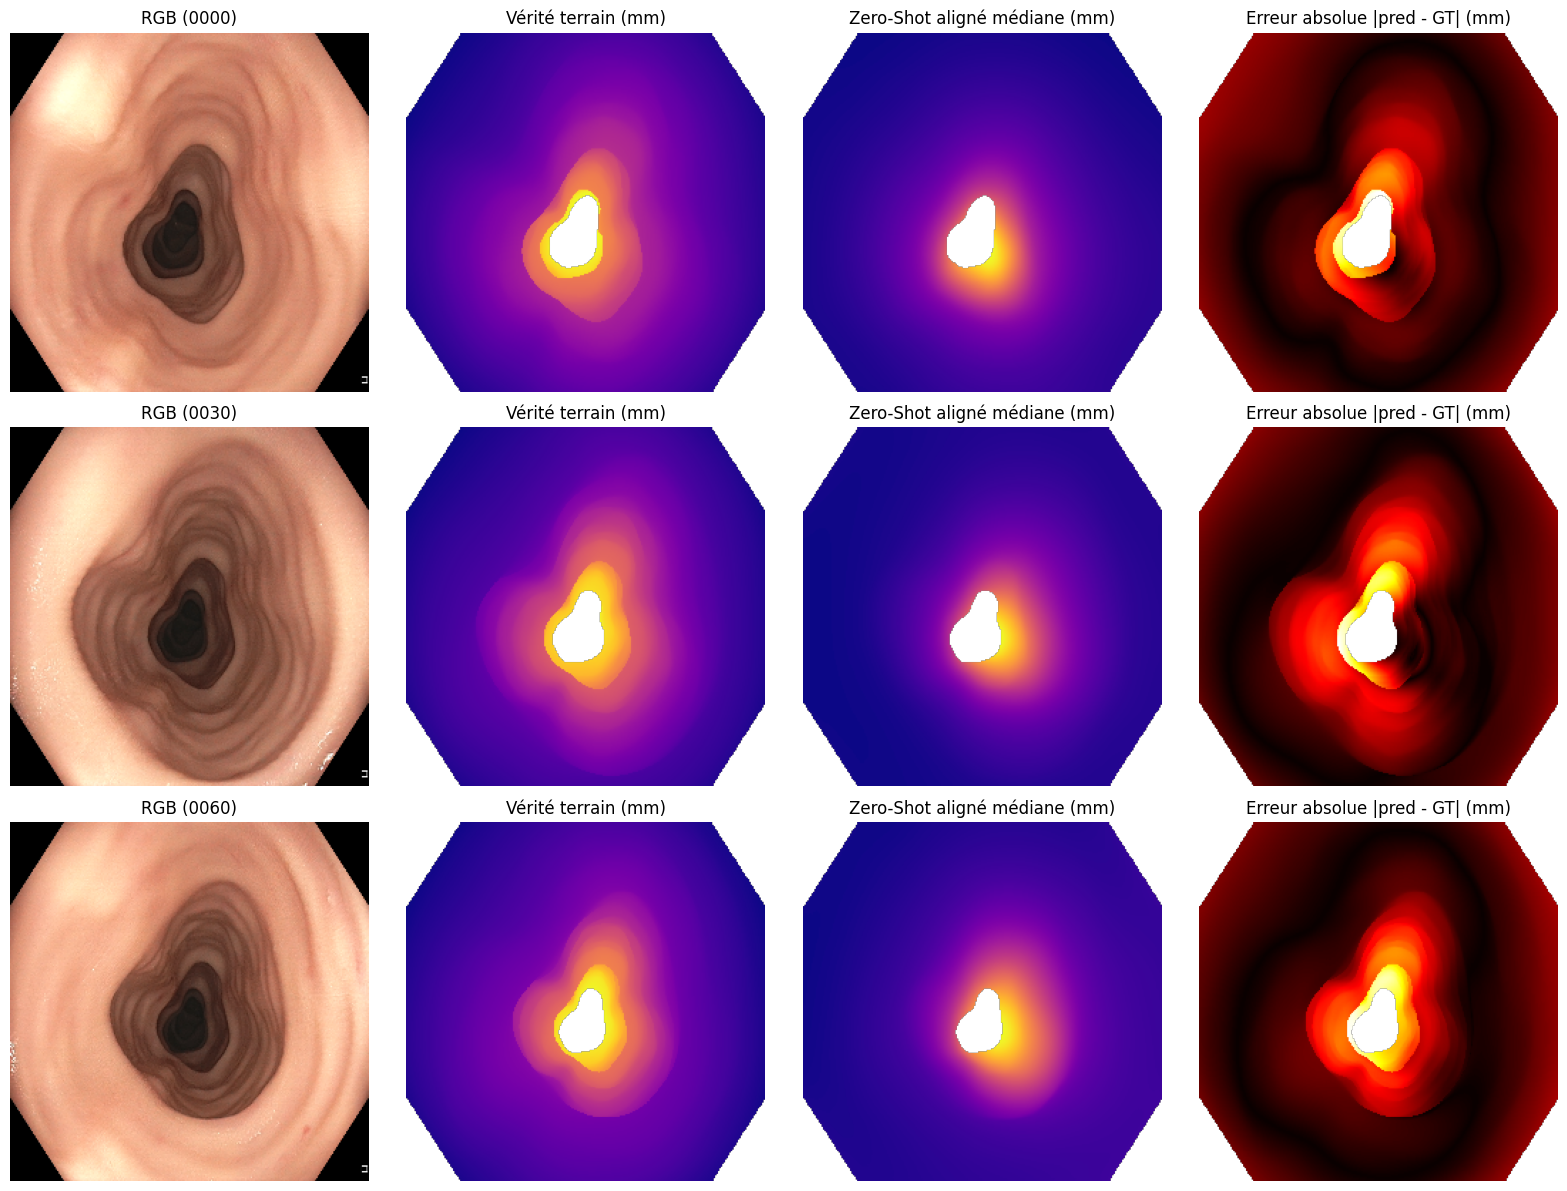

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from src.datasets import build_dataset
from src.metrics import align_prediction
from src.models import build_model
from src.utils import get_device

device = get_device("auto")
ds_test = build_dataset(base_cfg, split=EVAL_SPLIT)
model = build_model(base_cfg).to(device)
model.eval()

num_show = min(3, len(ds_test))
fig, axes = plt.subplots(num_show, 4, figsize=(16, 4 * num_show))
if num_show == 1:
    axes = axes[np.newaxis, :]

for row, idx in enumerate(np.linspace(0, len(ds_test) - 1, num_show, dtype=int)):
    sample = ds_test[int(idx)]
    img = sample["image"].unsqueeze(0).to(device)
    gt = sample["depth"].to(device)
    mask = sample["mask"].to(device)
    with torch.no_grad():
        pred_disp = model(img)[0]
        pred_mm = align_prediction(
            pred_disp,
            gt,
            mask,
            pred_is_disparity=True,
            align_mode="median",
            min_depth=float(base_cfg["data"]["min_depth_mm"]),
            max_depth=float(base_cfg["data"]["max_depth_mm"]),
        )

    gt_np = gt.squeeze(0).cpu().numpy()
    pred_np = pred_mm.cpu().numpy()
    mask_np = mask.squeeze(0).cpu().numpy()
    err_np = np.abs(pred_np - gt_np)

    axes[row, 0].imshow(sample["image"].permute(1, 2, 0).numpy())
    axes[row, 0].set_title(f"RGB ({sample['frame_id']})")
    axes[row, 1].imshow(np.ma.masked_where(~mask_np, gt_np), cmap="plasma")
    axes[row, 1].set_title("Vérité terrain (mm)")
    axes[row, 2].imshow(np.ma.masked_where(~mask_np, pred_np), cmap="plasma")
    axes[row, 2].set_title("Zero-Shot aligné médiane (mm)")
    axes[row, 3].imshow(np.ma.masked_where(~mask_np, err_np), cmap="hot")
    axes[row, 3].set_title("Erreur absolue |pred - GT| (mm)")
    for c in range(4):
        axes[row, c].axis("off")

plt.tight_layout()
plt.show()